<a href="https://colab.research.google.com/github/js-DigitalSurfer/ML/blob/main/03_Regresja_logistyczna.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regresja logistyczna

W tym ćwiczeniu zbudujemy klasyfikator oparty na regresji logistycznej.
Rozważymy klasyczny problem klasyfikacji odmian irysów na podstawie cech płatków. Jest to klasyczny już problem, często wykorzystywany przy porównywaniu różnych technik klasyfikacji. Więcej o pochodzeniu tych danych i problemie można przeczytać tu: [Iris_flower_data](https://en.wikipedia.org/wiki/Iris_flower_data_set)

### Przygotowanie środowiska programistycznego

In [6]:
import pandas as pd
import numpy as np
import scipy.optimize as so
import plotly.express as px

from sklearn import datasets


In [7]:
iris = datasets.load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["classes"] = iris.target
print(df.describe())
print(df.head())

       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)     classes  
count        150.000000  150.000000  
mean           1.199333    1.000000  
std            0.762238    0.819232  
min            0.100000    0.000000  
25%            0.300000    0.000000  
50%            1.300000    1.000000  
75%            1.800000    2.000000  
max            2.500000    2.000000  
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (

## Pre-processing, oraz analiza wizualna danych.

Najpierw przygotujemy uproszczoną wersję danych do klasyfikacji i nazwijmy to df_sub.
**Proszę:**
* wybrać kolumny ```'petal length (cm)', 'petal width (cm)', 'classes'```
* dla ułatwienia - zmienić nazwy kolumn na ```'length' i 'width'```
* stworzyć kolumnę ```label```, która będzie miałą następujące wartości: 0 dla classes 0 lub 1 oraz wartość 1 dla classes=2.
* usunąć powtarzające się wiersze




In [8]:
# 1. Wybór kolumn
df_sub = df[['petal length (cm)', 'petal width (cm)', 'classes']].copy()

# 2. Zmiana nazw kolumn
df_sub = df_sub.rename(columns={
    'petal length (cm)': 'length',
    'petal width (cm)': 'width'
})

# 3. Stworzenie kolumny 'label' (0 dla klas 0 i 1, oraz 1 dla klasy 2)
df_sub['label'] = np.where(df_sub['classes'] == 2, 1, 0) #warunek, wartosc jesli true, otherwise

# 4. Usunięcie powtarzających się wierszy
df_sub = df_sub.drop_duplicates()

# Sprawdzenie wyniku
print(df_sub.head())



   length  width  classes  label
0     1.4    0.2        0      0
2     1.3    0.2        0      0
3     1.5    0.2        0      0
5     1.7    0.4        0      0
6     1.4    0.3        0      0



Teraz przejdziemy do analizy danych. Korzystając z metod klasy DataFrame.

**Proszę:**

* narysować histogramy cech (width, length) w zależności od kolumny label (osobne kolory)
* zrób wykres px.scatter, gdzie x to width, y to length, color to label z wykorzystaniem parametrów marginal_x i marginal_y dla różnych wariantów (box, histogram itp.) i ostatecznie wybierz jeden wariant.

In [9]:

# Histogram dla długości (length)
fig_hist_len = px.histogram(
    df_sub,
    x="length",
    color="label",
    barmode="overlay",
    title="Rozkład długości płatka (length) w zależności od etykiety",
    opacity=0.7,
    nbins= 40,
    color_discrete_map={0: 'blue', 1: 'orange'} # przypisanie konkretnych kolorów dla czytelności
)
fig_hist_len.show()

# Histogram dla szerokości (width)
fig_hist_wid = px.histogram(
    df_sub,
    x="width",
    color="label",
    barmode="overlay",
    title="Rozkład szerokości płatka (width) w zależności od etykiety",
    opacity=0.7,
    nbins = 40,
    color_discrete_map={0: 'blue', 1: 'orange'}
)
fig_hist_wid.show()


In [10]:

df_sub["label_str"] = df_sub["label"].astype(str)
px.scatter(
    df_sub,
    x="width",
    y="length",
    color="label_str",
    marginal_x="box",   # inne opcje: "box", "violin", "rug"
    marginal_y="box"
)

## Hipoteza
Dla przypomnienia _hipoteza_ w regresji logistycznej ma postać:

$\qquad$ $h_\theta(x) = \frac{1}{1+\exp(-\theta x^T )}$.

W implementacji dobrze jest myśleć o tej funkcji tak:

$\qquad$ $h_\theta(x) = \frac{1}{1+f}$.

gdzie: $f = \exp(-\theta x^T)$

**Proszę** napisać funkcję ```logistic_func(x, theta)``` która:

* implementuje funkcję logistyczną
* jako argumenty przyjmuje parametry regresji logistycznej  $(\theta_{0}, \theta_{1}, ..., \theta_{i})$ oraz tablicę danych wejściowych $x$.
* w kodzie funkcji proszę rozszerzyć tablicę $x$ o dodatkową kolumnę jedynek, by parametr $\theta_{0}$ był traktowany na tej same zasadzie co pozostałe parametry
* ze względu na stabilność numeryczną obliczeń proszę ograniczyć wartości wykładnika w mianowniku do zakresu  $\pm18$

**Ostrzeżenie:** x to tablica która może zawierać wiele kolumn i wiele wierszy.

**Wskazówka**: ograniczając zakres zwracanych wartości proszę skorzystać z funkcji ```np.where()``` zaaplikowanej do wektora wartości wykładnika.

Proszę sprawdzić działanie funkcji na następujących danych testowych:
```Python
theta = np.array([1,1,2])
x = np.array([[5,5],
              [5,6],
              [-5,-5],
              [-5,-8]])
```
Oczekiwany wynik:
```
[9.99999887e-01 9.99999985e-01 8.31528028e-07 1.52299795e-08]
```

In [15]:
def logistic_func(theta, x):
      # dodaj kolumne jedynek
      ones = np.ones((x.shape[0], 1))
      X_new = np.hstack((ones, x))

      # policz argument funkcji (iloczyn macierzowy X i theta)
      arg = np.dot(X_new, theta)

      # uzyj np.where żeby ograniczyc wartosci parametru do [-18,18]
      # ograniczamy "arg", aby po nałożeniu minusa w np.exp(-arg) nie przekroczyć zakresu
      arg = np.where(arg > 18, 18, arg)
      arg = np.where(arg < -18, -18, arg)

      return 1.0/(1+np.exp(-arg))

theta = np.array([1,1,2])
x = np.array([[5,5],
              [5,6],
              [-5,-5],
              [-5,-8]])
res = logistic_func(theta, x)

# sprawdzenie poprawności rozmiaru listy
assert res.shape == (4,)
print(res)

[9.99999887e-01 9.99999985e-01 8.31528028e-07 1.52299795e-08]


## Funkcja log-wiarygodności (LLH):
Parametry regresji znajdujemy przez maksymalizację [funkcji log-wiarygodności](https://brain.fuw.edu.pl/edu/index.php/Uczenie_maszynowe_i_sztuczne_sieci_neuronowe/Wykład_6#Funkcja_wiarygodno.C5.9Bci):

$\qquad$ $l(\theta) = \log L(\theta) = \sum_{j=1}^m y^{(j)} \log h(x^{(j)}) + (1 - y^{(j)}) \log (1 - h(x^{(j)}))$,
gdzie:  

m - liczebność próbki

x - dane wejściowe, u nas length, width

y - dane wyjściowe, u nas label

h - postać zależności wyniku od danych wejściowych. U nas to jest funkcja logistyczna, czyli oczekujemy, że wzór y = h(x) dobrze opisuje zależność między danymi wejściowymi, a wyjściowymi.


<hr>

**Proszę** napisać funkcję ```log_likelihood(theta, x,y, model)``` która:

* implementuje funkcję log-wiarygodności
* jako argumenty przyjmuje parametry regresji logistycznej  $(\theta_{0}, \theta_{1}, ..., \theta_{i})$ oraz tablicę danych wejściowych $x, y$.
* ```model``` dla którego szukamy parametrów $\theta_{i}$ w naszym przypadku to będzie funkcja logistyczna: ```logistic_func```

**Uwaga**: argument $theta$ musi być pierwszy

In [19]:
def log_likelihood(theta, x, y, model):
    # 1. Obliczamy hipotezę h(x) za pomocą przekazanego modelu
    h = model(theta, x)

    # 2. Implementacja wzoru matematycznego dla wszystkich wierszy
    llh_elements = y * np.log(h) + (1 - y) * np.log(1 - h)

    # 3. Zsumowanie wyników ze wszystkich próbek (m)
    result = np.sum(llh_elements)
    return result

Maksymalizacja to zadanie optymalizacyjne - szukamy optymalnych parametrów, a kryterium optymalności to maksymalna wartość funkcji log-wiarygodności.
W tym ćwiczeniu zrobimy to za pomocą funkcji optymalizacyjnych z modułu [<tt>scipy.optimize</tt>]( http://docs.scipy.org/doc/scipy/reference/optimize.html#module-scipy.optimize).


Wynikają z tego dwie konsekwencje:
* funkcje te są przystosowane do szukania minimów funkcji celu (straty). Musimy więc podawać im jako argumenty funkcję minus log-wiarygodności
* niektóre algorytmy mogą działać szybciej jeśli zaimplementujemy jawnie postać pochodnej:

$\qquad$ $
\begin{array}{lcl}
\frac{\partial}{\partial \theta_i} l(\theta)  =\sum_{j=1}^m (y^{(j)}-h_\theta(x^{(j)}))x_i^{(j)}
\end{array}
$

**Proszę** napisać funkcję ```negative_log_likelihood(theta, x,y, model)``` która:

* zwraca funkcję log-wiarygodności pomnożoną przez $-1$

In [20]:
def negative_log_likelihood(theta, x, y, model):
  return -log_likelihood(theta, x, y, model)


**Proszę** napisać funkcję ```log_likelihood_derivative(theta, x,y, model)``` oraz ```negative_log_likelihood_derivative(theta, x,y, model)``` które:

* zwraca funkcję pochodną log-wiarygodności
* zwraca funkcję pochodną log-wiarygodności pomnożoną przez $-1$

**Uwaga**: mnożąc przez $x_{i}$ trzeba uwzględnić kolumnę jedynek

In [21]:
def log_likelihood_derivative(theta, x, y, model):

    ones = np.ones((x.shape[0], 1))
    X_new = np.hstack((ones, x))
    # odpowiedź modelu na dane
    h = model(theta, x)

    # różnica odpowiedzi modelu i wartości prawdziwej
    error = y - h

    # obliczenie pochodnej wysumowanej po wszyskich przykładach
    result = np.dot(X_new.T, error)


    #sprawdzenie poprawności rozmiaru wyniku
    assert result.shape == theta.shape
    return result

def negative_log_likelihood_derivative(theta, x, y, model):
    return -log_likelihood_derivative(theta, x, y, model)

## Procedura minimalizacji funkcji log-wiarygodności ze wsględu na parametry $\theta$ dla konkretnych danych.

W naszym przypadku mamy trzy parametry $\theta$ - mnożące odpowiednio 1, oraz kolumny Age i Fare.

**Proszę:**
* zainicjalizować parametry $\theta_{0}, \theta_{1}, \theta_{2}$ na wartości (0,0,0).
* obliczyć wartość i pochodną funkcji wiarygodności na danych, ```df```

Poprawny wynik to:
```Python
Wartość funkcji log-wiarygodności dla zbioru testowego = -71.39415959767437
Wartość pochodnej funkcji log-wiarygodności dla zbioru testowego = [-6.5  32.65 18.95]
```

In [22]:
# 1. Inicjalizacja parametrów theta na wartości (0, 0, 0) jako wektor pionowy lub poziomy
# Mamy 3 parametry: dla wyrazu wolnego (1), dla length oraz dla width
theta_start = np.array([0.0, 0.0, 0.0])

# 2. Przygotowanie danych wejściowych X (cechy) i y (prawdziwe etykiety) z df_sub
X_data = df_sub[['length', 'width']].values
y_data = df_sub['label'].values

# wartość funkcji log-wiarygodności
llh = log_likelihood(theta_start, X_data, y_data, logistic_func)

# wartość pochodnej
llh_derivative = log_likelihood_derivative(theta_start, X_data, y_data, logistic_func)

print("Wartość funkcji log-wiarygodności dla zbioru testowego = {}".format(llh))
print("Wartość pochodnej funkcji log-wiarygodności dla zbioru testowego = {}".format(llh_derivative))

Wartość funkcji log-wiarygodności dla zbioru testowego = -71.39415959767437
Wartość pochodnej funkcji log-wiarygodności dla zbioru testowego = [-6.5  32.65 18.95]


## Optymalizacja  

Funkcje optymalizujące zaczerpniemy z modułu scipy.optimize: ```scipy.optimize.fmin_bfgs```. Ponieważ funkcje te są zaimplementowane do mnimalizowania to zamiast maksymalizować funkcję log-wiarygodności będziemy minimalizować funkcję przemnożoną przez -1 czyli ```f=negative_log_likelihood``` oraz ```fprime=negative_log_likelihood_derivative```

**Proszę:**

* wywołać funckję ```scipy.optimize.fmin_bfgs``` z odpowiednimi argumentami.
* porównać liczbę wywołań i czas wykonywania komórki z i bez podania explicite postaci pochodnej
(https://ipython.readthedocs.io/en/stable/interactive/magics.html?highlight=%25time#cell-magics)

Oczekiwany wynik:
```
Optymalne wartości parametrów theta: [-40.55228421   5.41888077   8.53935285]
Wartość funkcji log-wiarygodności dla optymalnych parametrów: -9.340587741669628
```

In [23]:
%%time
# komenda ``time``` włącza licznik czasu wykonywania komórki

model = logistic_func

# poszukiwanie optymalnych wartości parametrów theta

theta_opt = so.fmin_bfgs(
    f=negative_log_likelihood,
    x0=theta_start,
    fprime=negative_log_likelihood_derivative,
    args=(X_data, y_data, model)
)


# wartość LLH z optymalnymi parametrami
llh = log_likelihood(theta_opt, X_data, y_data, logistic_func)

print('Optymalne wartości parametrów theta: {}'.format(theta_opt))
print("Wartość funkcji log-wiarygodności dla optymalnych parametrów: {}".format(llh))

Optimization terminated successfully.
         Current function value: 9.340588
         Iterations: 25
         Function evaluations: 28
         Gradient evaluations: 28
Optymalne wartości parametrów theta: [-40.55233066   5.41888881   8.53935692]
Wartość funkcji log-wiarygodności dla optymalnych parametrów: -9.340587741675279
CPU times: user 7.73 ms, sys: 936 µs, total: 8.66 ms
Wall time: 12.5 ms


## Wyniki modelu
Wyniki regresji logistycznej możemy odbierać na dwa sposoby:
* obliczyć wartość hipotezy dla badanego wejścia i dopasowanych parametrów: miara ta ma interpretację prawdopodobieństwa przynależności wejścia do klasy 1,
* dopisać funkcję wykonującą klasyfikację, tzn. porównanie wartości hipotezy z 1/2:
  * dla wartości hipotezy > 1/2 klasyfikacja zwraca 1,
  * w przeciwnym razie 0.
  
  
**Proszę** napisać funkcję ```classification(theta, x, model)```  która:
* jako argument przyjmuje wektor parametrów modelu $\theta$, tablicę danych wejściowych $x$, oraz $model$
* zwraca listę klasyfikacyjną: $1$ gdy $model(x)>0.5$, a $0$ w przeciwnym przypadku

In [27]:
def classification(theta, x, model):

    # 1. Obliczamy wartości prawdopodobieństwa (hipotezę) dla podanych danych
    probabilities = model(theta, x)

    # 2. Porównujemy prawdopodobieństwa z progiem 0.5.
    # Wynik to tablica wartości True/False, którą zamieniamy na 1/0 za pomocą .astype(int)
    model_result = (probabilities > 0.5).astype(int)

    return model_result

In [25]:
df_sub

,length,width,classes,label,label_str
0,1.4,0.2,0,0,0
2,1.3,0.2,0,0,0
3,1.5,0.2,0,0,0
5,1.7,0.4,0,0,0
6,1.4,0.3,0,0,0
...,...,...,...,...,...
145,5.2,2.3,2,1,1
146,5.0,1.9,2,1,1
147,5.2,2.0,2,1,1
148,5.4,2.3,2,1,1


## Procedura klasyfikacji

**Proszę:**

* korzystając z modelu ```logistic_func``` wraz z parametrami zwróconymi przez procedurę optymalizacyjną obliczyć prawdopodobieństwo przynależności do klasy 1 dla wartości length=1.5 cm i width=3.0.

* korzystając z funkcji "classification" wyznaczyć czy kwiat należy do   klasy $0$ czy $1$.

Oczekiwany wynik:
```
Przynależność do klasy 1 wynosi: 0.0011
Kwiat zalicza się do klasy : [0]
```

In [28]:
# Przygotowanie danych dla kwiatu z polecenia: length=1.5 cm i width=3.0 cm
# Zauważ, że dane podajemy jako tablica dwuwymiarowa (macierz z jednym wierszem)
x_sample = np.array([[1.5, 3.0]])

# 1. Obliczenie prawdopodobieństwa przynależności do klasy 1 przy użyciu optymalnych wag theta_opt
p = logistic_func(theta_opt, x_sample)

# 2. Wyznaczenie ostatecznej klasy (0 lub 1) za pomocą funkcji classification
class_number = classification(theta_opt, x_sample, logistic_func)

print(f"Przynależność do klasy 1 wynosi: {p[0]:.4f}")
print(f"Kwiat zalicza się do klasy : {class_number}")

Przynależność do klasy 1 wynosi: 0.0011
Kwiat zalicza się do klasy : [0]


**Proszę:**

* narysować punkty pokolorowane zgodnie z przynależnością do klas
* dorysować prostą rozgraniczającą obszary "1" od "0".   Prosta ma ona równanie

$\qquad$ $h_\theta(x)=1/2$,

tzn:

$\qquad$ $\theta x^T = 0$

czyli

$\theta_0 +\theta_1 x_1 + \theta_2 x_2 =0 $

Przekształcając to do równania prostej we współrzędnych $(x_1,x_2)$ mamy:

$- \theta_2 x_2 = \theta_0 +\theta_1 x_1 $

$ x_2 = - \frac{1}{\theta_2}( \theta_0 +\theta_1 x_1 )$

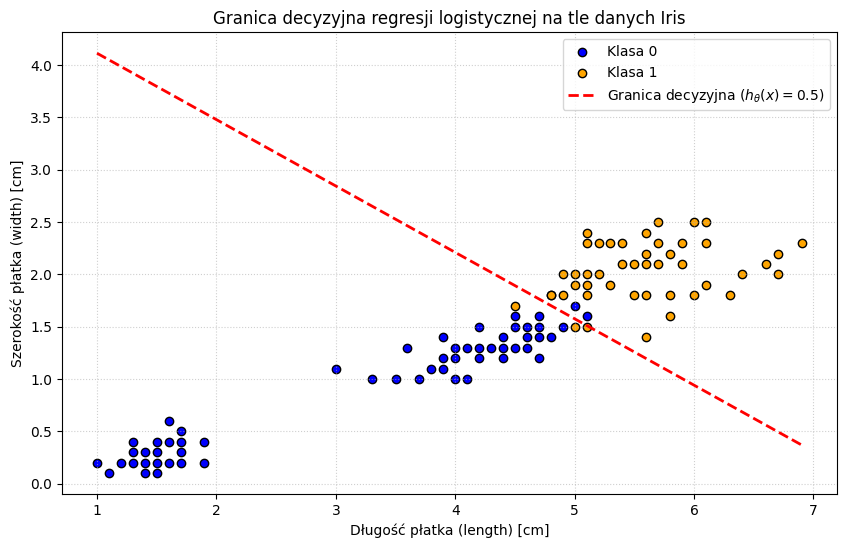

In [30]:
import plotly.express as px
import plotly.graph_objects as go
import numpy as np
import matplotlib.pyplot as plt


# 1. Wyciągnięcie danych do narysowania punktów
x1_data = df_sub['length'].values
x2_data = df_sub['width'].values
labels = df_sub['label'].values

# Utworzenie okna wykresu
plt.figure(figsize=(10, 6))

# 2. Rysowanie punktów pokolorowanych zgodnie z przynależnością do klas
# Używamy maskowania logicznego, aby narysować każdą klasę osobno z własną etykietą i kolorem
plt.scatter(x1_data[labels == 0], x2_data[labels == 0], color='blue', label='Klasa 0', edgecolors='k')
plt.scatter(x1_data[labels == 1], x2_data[labels == 1], color='orange', label='Klasa 1', edgecolors='k')


# 3. Generowanie punktów dla prostej rozgraniczającej (Granica decyzyjna)
# Bierzemy 100 punktów od wartości minimalnej do maksymalnej cechy 'length'
x1_vals = np.linspace(x1_data.min(), x1_data.max(), 100)


# Implementacja przekształconego wzoru: x2 = -1/theta2 * (theta0 + theta1 * x1)
theta0 = theta_opt[0]
theta1 = theta_opt[1]
theta2 = theta_opt[2]
x2_vals = -(theta0 + theta1 * x1_vals) / theta2


# 4. Dorysowanie prostej rozgraniczającej obszary "1" od "0"
plt.plot(x1_vals, x2_vals, color='red', linestyle='--', linewidth=2, label='Granica decyzyjna ($h_\\theta(x) = 0.5$)')


# 5. Dekoracja wykresu (opisy osi, tytuł, legenda)
plt.xlabel('Długość płatka (length) [cm]')
plt.ylabel('Szerokość płatka (width) [cm]')
plt.title('Granica decyzyjna regresji logistycznej na tle danych Iris')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

# Wyświetlenie ostatecznego wykresu
plt.show()



1.   Element listy
2.   Element listy



Wariant rysunku z użyciem biblioteki seaborn

# Zadanie domowe

Zastosowanie regresji liniowej do innego rodzaju danych.

**Proszę:**

* wygenerować syntetyczne wyniki 100 egzaminów z biologi i matematyki według rozkładu płaskiego w zakresie ```[0,100]``` punktów
* proszę wygenerować efekt rekrutacji na studia według wzoru:

$$
\text{zdał} =\sqrt{(\text{wynik z matematyki}-50)^{2} + (\text{wynik z biologii}-50)^{2}}>25
$$
  

* narysować rozkład osób które zdały/nie zdały na płaszczyźnie ```x="matematyka", y="biologia"```
* przeprowadzić trening regresji logistycznej dla tych danych
* narysować krzywą rozdzielającą kategorie
* odpowiedzieć na pytanie **"Czy krzywa poprawnie rozdziela kategorie?"**

In [ ]:
nPoints = 1000
...
